# Axis 5 — Memory Hierarchy & Expert Placement (Windows dGPU / PyTorch)

**Question (team page).** How does placing experts across memory tiers affect end-to-end latency and throughput?

**Tiers.** The dGPU machine has **three**: **VRAM** (where the GPU computes from), **system RAM** (pinned, one PCIe copy away) and **disk** (NVMe). The Mac has two (unified memory, disk), so the Mac question — *which experts should live in the fast tier, fixed or changing?* — is asked here for VRAM, **with and without a RAM tier** underneath.

## Strategies for the VRAM tier, at the same budget B (experts in VRAM)
| Strategy | VRAM tier | Changes over time? |
|---|---|---|
| **static** | the B − 64 experts used most in a *profiling* run, pinned for good, plus a 64-slot staging area (the minimum to compute any layer call) | almost not at all |
| **hybrid** | B/2 pinned hottest experts + B/2 LRU slots | half |
| **dynamic** | B LRU slots, nothing pinned | fully |

## The RAM tier
| Layout | A VRAM miss is served from |
|---|---|
| **three tiers** (`ram_tier` = R) | the RAM tier if it holds the expert (one host → VRAM copy), else disk → RAM tier → VRAM. The RAM tier is R pinned buffers managed by LRU; it never holds the full bank (R < 1,024). |
| **two tiers** (`ram_tier` = 0) | disk → pinned staging buffer → VRAM, as on the Mac |

* Profiling uses a **different** set of prompts from the evaluation, so pinning is not tuned to the test.
* Pinned VRAM experts are loaded before the run (startup cost reported separately, not counted as misses).
* Every disk read is unbuffered, so the Windows file cache is not a hidden fourth tier.
* `runs` holds the three-tier runs (the dGPU's headline result, used by the cross-device figures); `runs_two_tier` holds the same runs without the RAM tier.

**Hypothesis.** A hierarchy that keeps frequently reused experts in the fastest tier, stages warm experts in an intermediate tier, and fetches only cold tails from disk beats a single uniform policy. `MOE_SMOKE=1` runs a tiny configuration.

In [1]:
import os, sys, time, json, importlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

# Shared code: the `moe` package in src/. `pip install -e ".[windows]"` installs it; the path
# line below makes the notebook work without installing.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src' / 'moe').is_dir())
if str(ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(ROOT / 'src'))
from moe import common, torch_cache as tc, results as rs, figures as fg   # tc is Windows (PyTorch)
for m in (common, tc, rs, fg):
    importlib.reload(m)                # pick up edits to src/moe without restarting the kernel

# MOE_SMOKE=1 runs a tiny configuration end to end (used to test the notebook).
SMOKE = os.environ.get('MOE_SMOKE') == '1'
AXIS_DIR = ROOT / 'experiments' / 'axis-5-memory-tiering'
RESULTS = (ROOT / 'experiments' / '.cache' / 'smoke' / 'axis-5-memory-tiering') if SMOKE else (AXIS_DIR / 'results')
RESULTS.mkdir(parents=True, exist_ok=True)

DEVICE = 'windows-dgpu'                 # results file: <axis>/results/windows-dgpu.json
AXIS = 'axis-5-memory-tiering'
TABLES = {}                             # every table this run produces, saved at the end

GPU = tc.default_device()               # the dedicated GPU (Windows + CUDA only); K counts experts in its VRAM
torch.set_grad_enabled(False)

plt.rcParams.update({'figure.figsize': (11, 5), 'font.size': 10, 'axes.grid': True, 'grid.alpha': 0.3})
print('SMOKE run' if SMOKE else 'Full run', '| results ->', RESULTS.relative_to(ROOT))
print(tc.system_info(GPU))

Full run | results -> experiments\axis-5-memory-tiering\results
{'os': 'Windows-11-10.0.26300-SP0', 'cpu': 'Intel64 Family 6 Model 183 Stepping 1, GenuineIntel', 'ram_GB': 16.8, 'python': '3.14.7', 'torch': '2.11.0+cu128', 'transformers': '5.22.2', 'device': 'cuda', 'expert_reads': 'windows-unbuffered', 'gpu': 'NVIDIA GeForce RTX 5050 Laptop GPU', 'vram_GB': 8.55, 'cuda': '12.8'}


## Configuration

In [2]:
BUDGETS = [192, 384, 576]          # experts resident in VRAM (bank = B x 12.6 MB)
RAM_TIER = 512                     # experts in the pinned-RAM tier (6.4 GB); 0 = two tiers only
STAGING = 64                       # dynamic slots kept by the static strategy
HYBRID_PIN_FRACTION = 0.5
PROFILE_PER_DOMAIN = 2             # profiling prompts per kind (disjoint from evaluation; max 2+2)
EVAL_PER_DOMAIN = 2
MAX_NEW_TOKENS = 48
REPLAY_BUDGETS = [128, 192, 256, 384, 512, 576, 768]   # denser curve by exact replay

if SMOKE:
    BUDGETS, PROFILE_PER_DOMAIN, EVAL_PER_DOMAIN, MAX_NEW_TOKENS = [192], 1, 1, 6
    REPLAY_BUDGETS, RAM_TIER = [128, 192, 256], 64
print('VRAM budgets:', BUDGETS, '| RAM tier:', RAM_TIER, 'experts | strategies: static, hybrid, dynamic')
CONFIG = rs.config_from(globals())   # recorded in the results file

VRAM budgets: [192, 384, 576] | RAM tier: 512 experts | strategies: static, hybrid, dynamic


## Model (non-expert weights only) and correctness gate

In [3]:
MODEL_DIR = tc.default_model_dir()       # allenai/OLMoE-1B-7B-0125-Instruct (BF16), downloaded beforehand
assert list(MODEL_DIR.glob('model*.safetensors')),     f'Checkpoint not found in {MODEL_DIR}: download allenai/OLMoE-1B-7B-0125-Instruct there first.'
model, tokenizer, index = tc.load_model(MODEL_DIR, device=GPU)
print(index.describe())
print(f'Non-expert weights resident on {GPU}: {tc.non_expert_bytes(model) / 1e9:.2f} GB '
      f'| expert reads: {tc.ExpertReader(index).mode}')
# Measured ONCE, before any expert bank exists: free VRAM read later in the run is unreliable.
SAFE_K = tc.max_safe_capacity(index, GPU)
print(f'Largest K that fits in the VRAM free right now: {SAFE_K} (bank {SAFE_K * index.expert_bytes / 1e9:.1f} GB)')

# Correctness gate: one layer through the K-slot bank vs the stock transformers layer
# (all 64 experts of that layer resident, eager expert loop). Must be bit-identical.
diff = tc.check_layer_exactness(model, index, capacity=64)
assert diff == 0.0, diff
print(f'Layer exactness vs stock transformers: max |diff| = {diff}')

W1112 10:40:02.948000 26116 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


16 layers x 64 experts = 1024 logical experts | 12.58 MB each (BF16) | full bank 12.9 GB on disk
Non-expert weights resident on cuda: 0.95 GB | expert reads: windows-unbuffered
Largest K that fits in the VRAM free right now: 453 (bank 5.7 GB)
Layer exactness vs stock transformers: max |diff| = 0.0


In [4]:
# The RAM tier must fit in RAM next to everything else (pinned memory cannot be paged out).
SAFE_RAM = tc.max_host_capacity(index)
R = min(RAM_TIER, SAFE_RAM)
if R < RAM_TIER:
    print(f'RAM tier reduced from {RAM_TIER} to {R} experts to fit in the RAM free right now.')
host = tc.HostTier(index, R) if R else None          # allocated once, emptied before every run
if host is not None:
    print(f'RAM tier: {R} experts = {host.bytes / 1e9:.1f} GB | page-locked: {host.pinned} '
          f'(allocated in {host.alloc_s:.1f}s)')

RAM tier reduced from 512 to 0 experts to fit in the RAM free right now.


## Profiling run: which experts are hot?

In [5]:
# Per kind of request, the first PROFILE_PER_DOMAIN prompts are used to find hot experts and the
# following EVAL_PER_DOMAIN are the held-out evaluation traffic (same split as the Mac).
prompt_file = rs.load_prompts(AXIS_DIR)   # axis-5-memory-tiering/prompts.json, shared by every device
PROMPTS = prompt_file['PROMPTS']
profile_reqs = tc.requests(PROMPTS, n_per_domain=PROFILE_PER_DOMAIN, order='interleave')
eval_reqs = tc.requests(PROMPTS, n_per_domain=EVAL_PER_DOMAIN, order='interleave', offset=PROFILE_PER_DOMAIN)
assert not {p['text'] for p in profile_reqs} & {p['text'] for p in eval_reqs}

cache = tc.ExpertCache(index, min(256, SAFE_K), 'LRU', device=GPU)   # outputs do not depend on K
_, rec = tc.run_workload(model, tokenizer, cache, profile_reqs, MAX_NEW_TOKENS, log=None)
cache.close(); tc.detach_cache(model)
prof = tc.events_frame(rec.events)
ranking = prof.groupby(['layer', 'eid']).size().sort_values(ascending=False)
hot = [tuple(map(int, k)) for k in ranking.index]
print(f'profiling: {len(profile_reqs)} requests, {len(prof):,} accesses, {len(hot)} distinct experts')
print('top-10 experts (layer, id):', hot[:10])
print('share of accesses covered by the top 128 / 256 / 512:',
      [f'{ranking.iloc[:n].sum() / ranking.sum():.0%}' for n in (128, 256, 512)])

profiling: 8 requests, 54,611 accesses, 1021 distinct experts
top-10 experts (layer, id): [(0, 6), (12, 43), (9, 5), (5, 0), (7, 17), (0, 41), (6, 18), (11, 47), (0, 23), (6, 5)]
share of accesses covered by the top 128 / 256 / 512: ['24%', '42%', '69%']


## Real runs on the evaluation requests
Every VRAM budget that fits × every strategy × {three tiers, two tiers}. Each run starts with an empty VRAM cache and an empty RAM tier. Exact replay of both tiers is asserted against the real counters.

In [6]:
def make_strategy(name, B):
    if name == 'dynamic':
        return tc.make_policy('LRU', B), []
    n_pin = B - STAGING if name == 'static' else int(B * HYBRID_PIN_FRACTION)
    pins = hot[:n_pin]
    return tc.TieredPolicy(B, pins, 'LRU'), pins

timed = [b for b in BUDGETS if b <= SAFE_K]
assert timed, f'No budget fits in free VRAM (largest safe K = {SAFE_K}). Close other GPU programs and re-run.'
if len(timed) < len(BUDGETS):
    print(f'Not timed (bank would not fit in VRAM): {[b for b in BUDGETS if b > SAFE_K]} -> see the replay curve below')
tiers = [R, 0] if R else [0]
rows, traces = [], {}
for B in timed:
    for ram in tiers:
        for strat in ['static', 'hybrid', 'dynamic']:
            tc.free_memory(); tc.reset_peak_memory(GPU)
            pol, pins = make_strategy(strat, B)
            if ram:
                host.reset()
            cache = tc.ExpertCache(index, B, pol, device=GPU, host_tier=host if ram else None)
            startup_ms = cache.preload(pins)
            t0 = time.perf_counter()
            df, rec = tc.run_workload(model, tokenizer, cache, eval_reqs, MAX_NEW_TOKENS, log=None)
            s = cache.summary()
            p2, _ = make_strategy(strat, B)
            if ram:
                hits, ram_hits = tc.replay_two_tier(rec.events, p2, ram)
                assert int(ram_hits.sum()) == s['ram_hits'], 'RAM-tier replay mismatch'
            else:
                hits = tc.replay(rec.events, p2)
            assert int(hits.sum()) == s['hits'], 'replay mismatch'
            dec_tok = (df.new_tokens - 1).sum()
            acc = tc.events_frame(rec.events)
            rows.append({'B': B, 'strategy': strat, 'ram_tier': ram, 'pinned': len(pins), 'hit_rate': s['hit_rate'],
                         'decode_hit_rate': hits[(acc.phase == 'decode').to_numpy()].mean(),
                         'ram_hit_rate': s.get('ram_hit_rate', float('nan')),
                         'GB_loaded': s['GB_loaded'], 'disk_GB': s['disk_GB'], 'io_s': s['io_ms'] / 1000,
                         'disk_s': s['disk_s'], 'h2d_s': s['h2d_s'],
                         'startup_s': startup_ms / 1000, 'startup_GB': len(pins) * index.expert_bytes / 1e9,
                         'decode_tok_s': dec_tok / df.decode_s.sum(), 'ttft_mean_s': df.ttft_s.mean(),
                         'wall_s': time.perf_counter() - t0, 'peak_GB': tc.peak_memory_gb(GPU)})
            traces[(B, ram, strat)] = rec.events
            cache.close(); tc.detach_cache(model)
            r = rows[-1]
            print(f'B={B} RAM={ram:4d} {strat:8s}: VRAM hit {r["hit_rate"]:.1%} (decode {r["decode_hit_rate"]:.1%}) | '
                  f'RAM hit {r["ram_hit_rate"]:.1%} | {r["disk_GB"]:.1f} GB from disk | {r["decode_tok_s"]:.2f} tok/s | '
                  f'TTFT {r["ttft_mean_s"]:.2f}s | startup {r["startup_s"]:.1f}s')
res = pd.DataFrame(rows)
TABLES['runs_all'] = res
TABLES['runs'] = res[res.ram_tier == tiers[0]].reset_index(drop=True)          # headline: three tiers
if R:
    TABLES['runs_two_tier'] = res[res.ram_tier == 0].reset_index(drop=True)
res.style.format(precision=2)

Not timed (bank would not fit in VRAM): [576] -> see the replay curve below
B=192 RAM=   0 static  : VRAM hit 22.9% (decode 24.2%) | RAM hit nan% | 529.8 GB from disk | 2.06 tok/s | TTFT 3.23s | startup 0.6s
B=192 RAM=   0 hybrid  : VRAM hit 26.2% (decode 28.3%) | RAM hit nan% | 507.4 GB from disk | 2.18 tok/s | TTFT 3.34s | startup 0.5s
B=192 RAM=   0 dynamic : VRAM hit 37.8% (decode 42.7%) | RAM hit nan% | 427.5 GB from disk | 2.65 tok/s | TTFT 3.69s | startup 0.0s
B=384 RAM=   0 static  : VRAM hit 49.7% (decode 51.7%) | RAM hit nan% | 345.7 GB from disk | 3.06 tok/s | TTFT 2.50s | startup 1.6s
B=384 RAM=   0 hybrid  : VRAM hit 60.4% (decode 65.3%) | RAM hit nan% | 272.3 GB from disk | 4.01 tok/s | TTFT 2.95s | startup 1.0s
B=384 RAM=   0 dynamic : VRAM hit 61.1% (decode 67.9%) | RAM hit nan% | 267.7 GB from disk | 4.47 tok/s | TTFT 3.32s | startup 0.0s


,B,strategy,ram_tier,pinned,hit_rate,decode_hit_rate,ram_hit_rate,GB_loaded,disk_GB,io_s,disk_s,h2d_s,startup_s,startup_GB,decode_tok_s,ttft_mean_s,wall_s,peak_GB
0,192,static,0,128,0.23,0.24,nan,529.75,529.75,188.93,134.42,54.44,0.63,1.61,2.06,3.23,208.36,3.39
1,192,hybrid,0,96,0.26,0.28,nan,507.38,507.38,180.81,128.36,52.38,0.49,1.21,2.18,3.34,199.60,3.39
2,192,dynamic,0,0,0.38,0.43,nan,427.50,427.50,153.56,109.13,44.36,0.00,0.00,2.65,3.69,171.56,3.39
3,384,static,0,320,0.50,0.52,nan,345.70,345.70,124.41,89.21,35.15,1.58,4.03,3.06,2.50,142.80,5.80
4,384,hybrid,0,192,0.60,0.65,nan,272.27,272.27,99.16,71.29,27.82,1.02,2.42,4.01,2.95,117.46,5.80
5,384,dynamic,0,0,0.61,0.68,nan,267.69,267.69,95.03,67.89,27.09,0.00,0.00,4.47,3.32,110.87,5.80


## Denser budget curve by exact replay
The evaluation access stream is the same for every strategy (outputs do not depend on the cache), so each strategy can be replayed at more budgets — including ones too large to time on this GPU — with and without the RAM tier. `GB_read` is what comes from disk (with the RAM tier when there is one); `GB_to_vram` is every VRAM miss.

In [7]:
events = next(iter(traces.values()))
acc = tc.events_frame(events)
dec = (acc.phase == 'decode').to_numpy()
rep = []
for B in REPLAY_BUDGETS:
    for strat in ['static', 'hybrid', 'dynamic']:
        if strat == 'static' and B <= STAGING:
            continue
        pol, _ = make_strategy(strat, B)
        if R:
            h, rh = tc.replay_two_tier(events, pol, R)
            from_disk = int((~rh).sum())
        else:
            h = tc.replay(events, pol)
            rh, from_disk = np.array([]), int((~h).sum())
        rep.append({'B': B, 'strategy': strat, 'hit_rate': h.mean(), 'decode_hit_rate': h[dec].mean(),
                    'ram_tier': R, 'ram_hit_rate': rh.mean() if len(rh) else float('nan'),
                    'GB_read': from_disk * index.expert_bytes / 1e9,
                    'GB_to_vram': (~h).sum() * index.expert_bytes / 1e9})
rep = pd.DataFrame(rep)
TABLES['replay'] = rep
rep.pivot(index='B', columns='strategy', values='hit_rate').style.format('{:.1%}').highlight_max(axis=1, color='#c6efce')

strategy,dynamic,hybrid,static
B,,,
128,35.1%,13.4%,13.4%
192,37.8%,26.2%,22.9%
256,46.9%,46.7%,31.7%
384,61.1%,60.4%,49.7%
512,71.8%,71.9%,69.2%
576,76.4%,76.8%,75.9%
768,88.3%,89.0%,90.3%


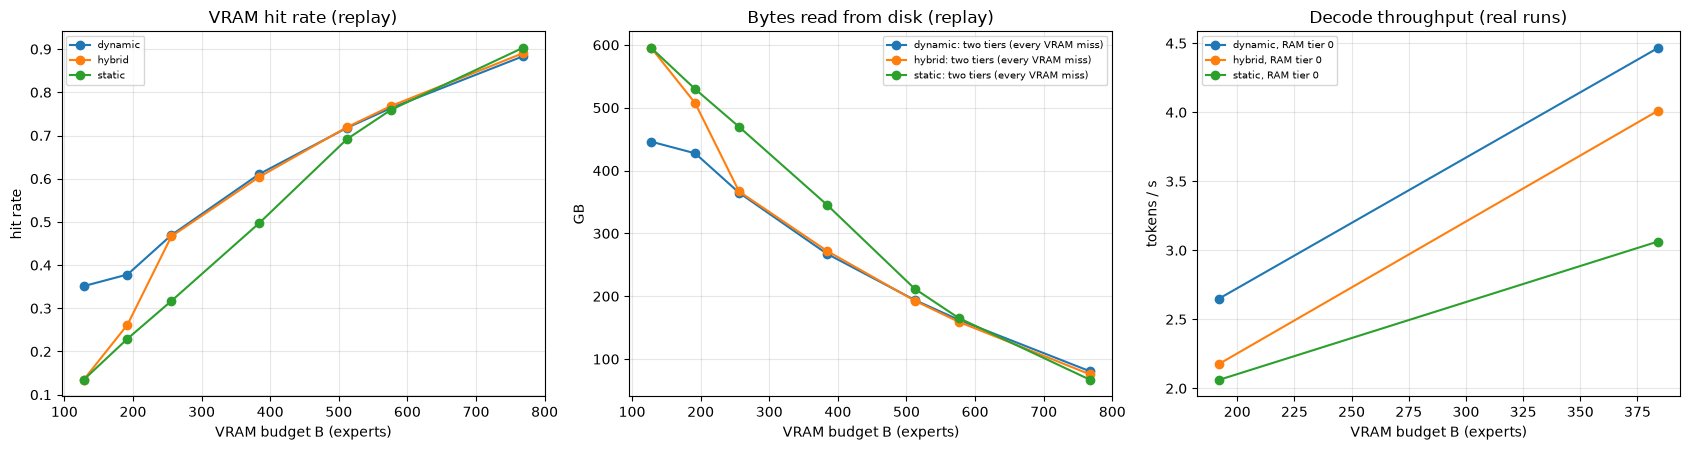

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for i, (strat, d) in enumerate(rep.groupby('strategy')):
    axes[0].plot(d.B, d.hit_rate, '-o', color=f'C{i}', label=strat)
    axes[1].plot(d.B, d.GB_to_vram, '-o', color=f'C{i}', label=f'{strat}: two tiers (every VRAM miss)')
    if R:
        axes[1].plot(d.B, d.GB_read, '--s', color=f'C{i}', label=f'{strat}: three tiers (RAM-tier misses)')
for i, (strat, d) in enumerate(res.groupby('strategy')):
    for ram, ls in ([(R, '-o'), (0, '--s')] if R else [(0, '-o')]):
        dd = d[d.ram_tier == ram]
        if len(dd):
            axes[2].plot(dd.B, dd.decode_tok_s, ls, color=f'C{i}', label=f'{strat}, RAM tier {ram}')
axes[0].set_title('VRAM hit rate (replay)'); axes[0].set_ylabel('hit rate')
axes[1].set_title('Bytes read from disk (replay)'); axes[1].set_ylabel('GB')
axes[2].set_title('Decode throughput (real runs)'); axes[2].set_ylabel('tokens / s')
for ax in axes:
    ax.set_xlabel('VRAM budget B (experts)'); ax.legend(fontsize=7)
fig.tight_layout(); plt.show()

## Hypothesis check (descriptive)

In [9]:
for B, d in rep.groupby('B'):
    d = d.set_index('strategy').hit_rate
    print(f'B={B:4d}: best = {d.idxmax():8s} ({d.max():.1%}); ' + ', '.join(f'{k} {v:.1%}' for k, v in d.items()))
for (B, ram), d in res.groupby(['B', 'ram_tier']):
    d = d.set_index('strategy')
    print(f'real B={B} RAM tier {ram}: fastest decode = {d.decode_tok_s.idxmax()} ({d.decode_tok_s.max():.2f} tok/s); '
          f'static pays {d.loc["static", "startup_s"]:.1f}s of startup loading ({d.loc["static", "startup_GB"]:.1f} GB)')
if R:
    both = res.pivot_table(index=['B', 'strategy'], columns='ram_tier', values='decode_tok_s')
    gain = both[R] / both[0] - 1
    print(f'\nRAM tier of {R} experts: decode throughput change vs two tiers: '
          + ', '.join(f'B={b} {s} {g:+.0%}' for (b, s), g in gain.items()))
print('\nA tiered layout "wins" only if pinning what was hot in profiling beats pure recency on new prompts;'
      ' the RAM tier helps when the VRAM misses it catches cost less than a disk read.')

B= 128: best = dynamic  (35.1%); static 13.4%, hybrid 13.4%, dynamic 35.1%
B= 192: best = dynamic  (37.8%); static 22.9%, hybrid 26.2%, dynamic 37.8%
B= 256: best = dynamic  (46.9%); static 31.7%, hybrid 46.7%, dynamic 46.9%
B= 384: best = dynamic  (61.1%); static 49.7%, hybrid 60.4%, dynamic 61.1%
B= 512: best = hybrid   (71.9%); static 69.2%, hybrid 71.9%, dynamic 71.8%
B= 576: best = hybrid   (76.8%); static 75.9%, hybrid 76.8%, dynamic 76.4%
B= 768: best = static   (90.3%); static 90.3%, hybrid 89.0%, dynamic 88.3%
real B=192 RAM tier 0: fastest decode = dynamic (2.65 tok/s); static pays 0.6s of startup loading (1.6 GB)
real B=384 RAM tier 0: fastest decode = dynamic (4.47 tok/s); static pays 1.6s of startup loading (4.0 GB)

A tiered layout "wins" only if pinning what was hot in profiling beats pure recency on new prompts; the RAM tier helps when the VRAM misses it catches cost less than a disk read.


## Notes for reading the results

* **Within-device trends first.** These are PyTorch / BF16 / CUDA numbers. The Mac runs MLX / F16 on unified memory: compare the *shape* of the curves across devices, not absolute values as one controlled experiment.
* **No page cache to purge.** Expert reads are unbuffered (`reads` = `windows-unbuffered` in the system info), so every miss really goes to the disk. If the reader had to fall back to buffered reads it prints a warning and the mode says `buffered`.
* **K is the VRAM tier.** The timed K values are those whose bank fits in the VRAM free at load (`SAFE_K`); larger K are replay-only (hit rates exact, no timing). Close other GPU programs before a full run.

* **Pinned RAM.** The RAM tier is page-locked memory, so it is real RAM and cannot be swapped. `SAFE_RAM` caps it to what was free at load.

## Save results
Every table above goes into **one file for this device**: `results/windows-dgpu.json`, with the configuration, prompts and machine it ran on.
The Mac and Windows iGPU notebooks write `mac.json` / `windows-igpu.json` next to it in the same format (see `experiments/README.md`).

In [10]:
CONFIG['SAFE_K'] = globals().get('SAFE_K')
CONFIG['RAM_TIER_USED'] = R
path = rs.save(RESULTS, AXIS, DEVICE, TABLES, config=CONFIG, prompts=rs.load_prompts(AXIS_DIR),
               system=tc.system_info(GPU))
print('Saved', path.relative_to(ROOT), '| tables:', {k: len(v) for k, v in TABLES.items()})

Saved experiments\axis-5-memory-tiering\results\windows-dgpu.json | tables: {'runs_all': 6, 'runs': 6, 'replay': 21}


## Cross-device figures
The report figures, drawn from every device's results file in this folder (colour = device). Only shown here;
`python -m moe.figures` writes them to `figures/` once all devices have results.

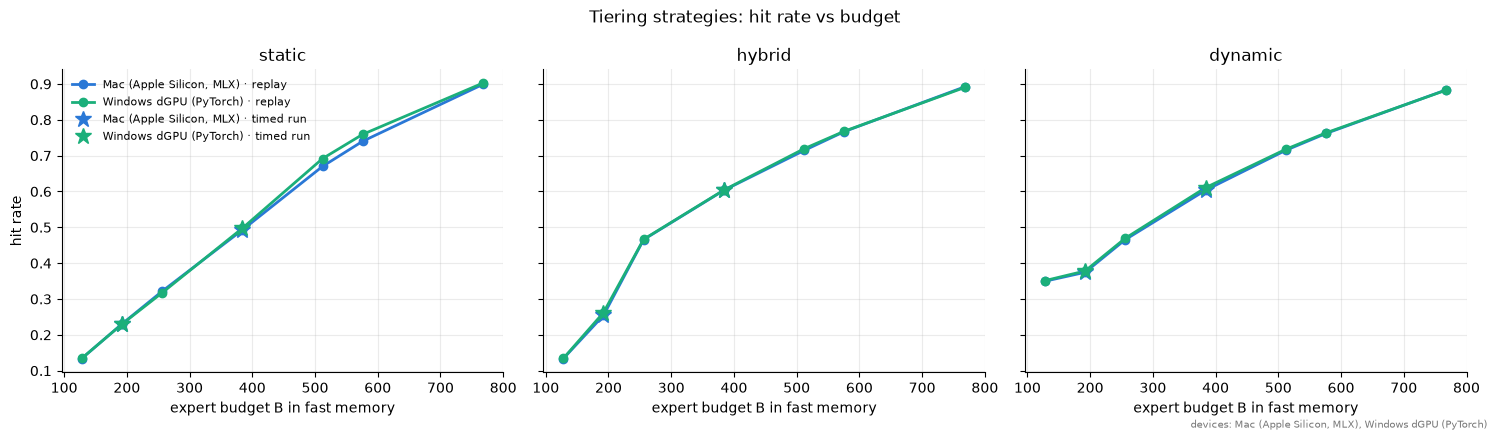

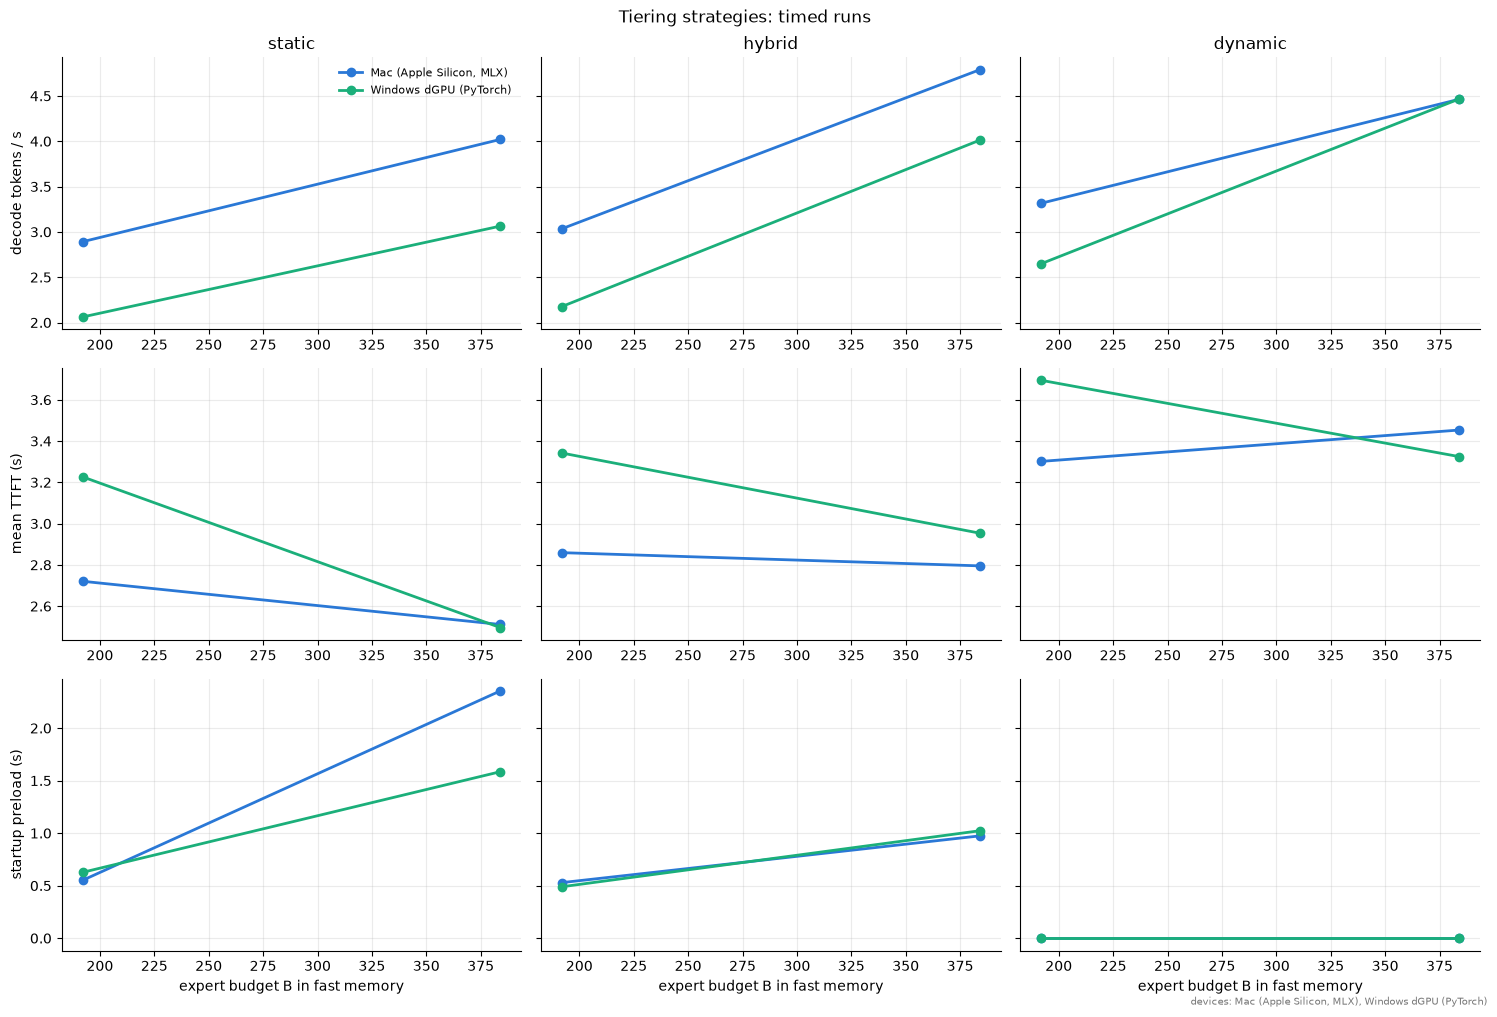

In [11]:
figs = fg.make(AXIS, RESULTS)